In [1]:
outpath = '/content/drive/MyDrive/John/Work/Research/01_In_Progress/ResearchMaterial/Deep Learning/code/'

In [3]:
# --- Celda 1: imports + datos  ---
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tf = transforms.ToTensor()
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=tf)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.02MB/s]


In [4]:
# --- Celda 2: Encoder ---
class Encoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # 28 -> 14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),  # 14 -> 7
            nn.Flatten(),
            nn.Linear(32*7*7, latent_dim),                         # bottleneck
        )
    def forward(self, x): return self.net(x)

# --- Decoder con conv-transpose ---
class Decoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 32*7*7), nn.ReLU(),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(16,  1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),# 14 -> 28
        )
    def forward(self, z): return self.net(z)

class AE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

In [5]:
# --- Celda 3: verificar tamaños de cada etapa ---
x = torch.randn(1, 1, 28, 28)
enc, dec = Encoder(16), Decoder(16)
z = enc(x); xhat = dec(z)
print(f"Input  : {tuple(x.shape)}")
print(f"Latente: {tuple(z.shape)}   <- cuello de botella  (16 << 784)")
print(f"Output : {tuple(xhat.shape)}")

def conv_transpose_out(size, k, s, p, op=0):
    return (size-1)*s - 2*p + k + op
print(f"\nConvT(K=3,S=2,P=1,OP=1) sobre 7 -> {conv_transpose_out(7,3,2,1,1)}")

Input  : (1, 1, 28, 28)
Latente: (1, 16)   <- cuello de botella  (16 << 784)
Output : (1, 1, 28, 28)

ConvT(K=3,S=2,P=1,OP=1) sobre 7 -> 14


ep 01 | BCE = 0.19387
ep 02 | BCE = 0.11412
ep 03 | BCE = 0.10594
ep 04 | BCE = 0.10148
ep 05 | BCE = 0.09878
ep 06 | BCE = 0.09691
ep 07 | BCE = 0.09552
ep 08 | BCE = 0.09444
ep 09 | BCE = 0.09357
ep 10 | BCE = 0.09286


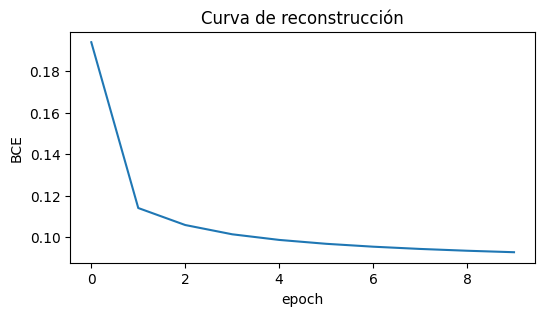

In [6]:
# --- Celda 4: entrenamiento del autoencoder ---
def train_ae(model, loader, epochs=10, lr=1e-3):
    crit = nn.BCELoss()
    opt  = optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        model.train(); tot = n = 0
        for x, _ in loader:                   # ¡ignoramos las etiquetas!
            x = x.to(device)
            xhat, _ = model(x)
            loss = crit(xhat, x)              # xhat ≈ x
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        hist.append(tot/n)
        print(f"ep {ep+1:02d} | BCE = {tot/n:.5f}")
    return hist

ae = AE(latent_dim=16).to(device)
hist = train_ae(ae, train_loader, epochs=10)

plt.figure(figsize=(6,3))
plt.plot(hist); plt.xlabel('epoch'); plt.ylabel('BCE'); plt.title('Curva de reconstrucción')
plt.show()

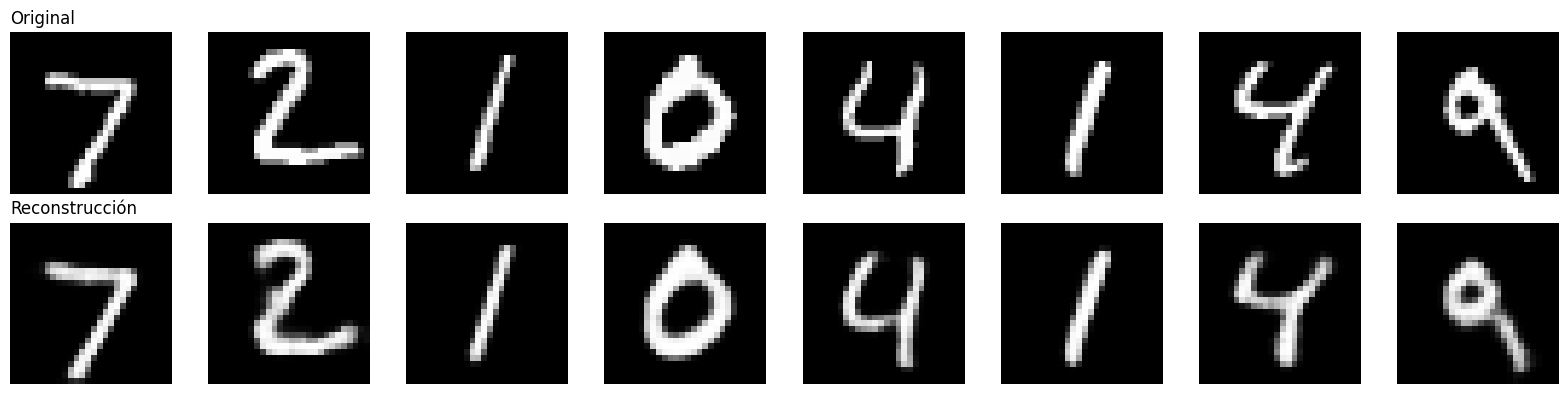

In [8]:
# --- Celda 5: reconstrucciones ---
def show_recon(model, loader, n=8):
    model.eval()
    x, _ = next(iter(loader)); x = x[:n].to(device)
    with torch.no_grad():
        xhat, _ = model(x)
    fig, axes = plt.subplots(2, n, figsize=(2*n, 4))
    for i in range(n):
        axes[0, i].imshow(x[i, 0].cpu(),    cmap='gray'); axes[0, i].axis('off')
        axes[1, i].imshow(xhat[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
    axes[0, 0].set_title('Original', loc='left')
    axes[1, 0].set_title('Reconstrucción', loc='left')
    plt.tight_layout(); plt.show()

show_recon(ae, test_loader)

torch.save(ae.state_dict(), f'{outpath}/ae_latent16.pt')